In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

In [2]:
df = pd.read_csv("/content/bank (1).csv")

In [3]:
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [4]:
df.shape

(11162, 17)

In [5]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')

In [6]:
df.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [10]:
df.isna().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.drop(columns=["day", "pdays"], inplace=True)

In [13]:
df

,age,job,marital,education,default,balance,housing,loan,contact,month,duration,campaign,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,may,1042,1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,may,1467,1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,may,1389,1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,may,579,1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,may,673,2,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,apr,257,1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,jun,83,4,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,aug,156,2,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,may,9,2,5,failure,no


In [14]:
df = df.replace("unknown", np.nan)

In [15]:
df.isna().sum()

,0
age,0
job,70
marital,0
education,497
default,0
balance,0
housing,0
loan,0
contact,2346
month,0


In [16]:
df["job"] = df["job"].fillna(df["job"].mode()[0])
df["marital"] = df["marital"].fillna(df["marital"].mode()[0])
df["education"] = df["education"].fillna(df["education"].mode()[0])
df["default"] = df["default"].fillna(df["default"].mode()[0])
df["housing"] = df["housing"].fillna(df["housing"].mode()[0])
df["loan"] = df["loan"].fillna(df["loan"].mode()[0])
df["contact"] = df["contact"].fillna(df["contact"].mode()[0])
df["month"] = df["month"].fillna(df["month"].mode()[0])
df["poutcome"] = df["poutcome"].fillna(df["poutcome"].mode()[0])

In [17]:
df["age"] = df["age"].fillna(df["age"].median())
df["balance"] = df["balance"].fillna(df["balance"].median())
df["duration"] = df["duration"].fillna(df["duration"].median())
df["campaign"] = df["campaign"].fillna(df["campaign"].median())
df["previous"] = df["previous"].fillna(df["previous"].median())

In [18]:
df.drop_duplicates()

,age,job,marital,education,default,balance,housing,loan,contact,month,duration,campaign,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,cellular,may,1042,1,0,failure,yes
1,56,admin.,married,secondary,no,45,no,no,cellular,may,1467,1,0,failure,yes
2,41,technician,married,secondary,no,1270,yes,no,cellular,may,1389,1,0,failure,yes
3,55,services,married,secondary,no,2476,yes,no,cellular,may,579,1,0,failure,yes
4,54,admin.,married,tertiary,no,184,no,no,cellular,may,673,2,0,failure,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,apr,257,1,0,failure,no
11158,39,services,married,secondary,no,733,no,no,cellular,jun,83,4,0,failure,no
11159,32,technician,single,secondary,no,29,no,no,cellular,aug,156,2,0,failure,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,may,9,2,5,failure,no


In [19]:
df.isna().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
month,0


In [22]:
df.head(-10)

,age,job,marital,education,default,balance,housing,loan,contact,month,duration,campaign,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,cellular,may,1042,1,0,failure,yes
1,56,admin.,married,secondary,no,45,no,no,cellular,may,1467,1,0,failure,yes
2,41,technician,married,secondary,no,1270,yes,no,cellular,may,1389,1,0,failure,yes
3,55,services,married,secondary,no,2476,yes,no,cellular,may,579,1,0,failure,yes
4,54,admin.,married,tertiary,no,184,no,no,cellular,may,673,2,0,failure,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11147,44,unemployed,married,secondary,no,0,no,no,cellular,nov,175,4,0,failure,no
11148,32,blue-collar,married,secondary,no,1,yes,no,cellular,may,102,1,0,failure,no
11149,46,entrepreneur,married,secondary,no,3317,no,no,cellular,nov,231,2,0,failure,no
11150,34,management,married,secondary,no,355,no,no,cellular,aug,314,3,0,failure,no


In [23]:
df["default"].value_counts()

,count
default,
no,10994
yes,168


In [24]:
df["deposit"].value_counts()

,count
deposit,
no,5873
yes,5289


In [25]:
df.describe()

,age,balance,duration,campaign,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,371.993818,2.508421,0.832557
std,11.913369,3225.413326,347.128386,2.722077,2.292007
min,18.000000,-6847.000000,2.000000,1.000000,0.000000
25%,32.000000,122.000000,138.000000,1.000000,0.000000
50%,39.000000,550.000000,255.000000,2.000000,0.000000
75%,49.000000,1708.000000,496.000000,3.000000,1.000000
max,95.000000,81204.000000,3881.000000,63.000000,58.000000


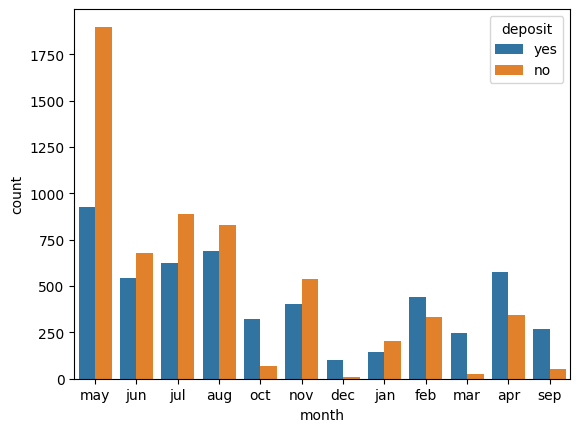

In [27]:
sns.countplot(data=df, x="month", hue="deposit")
plt.show()

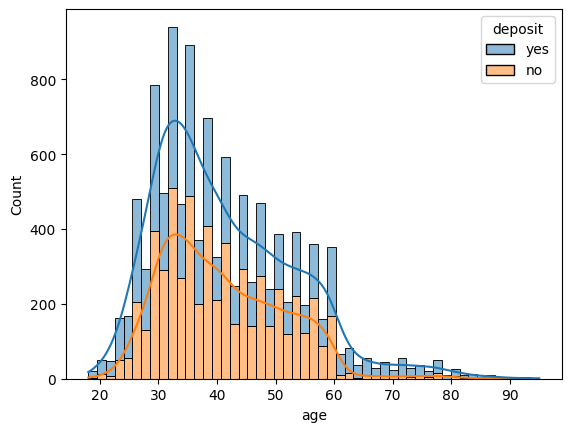

In [28]:
sns.histplot(data=df, x="age", hue="deposit", multiple="stack", kde=True)
plt.show()

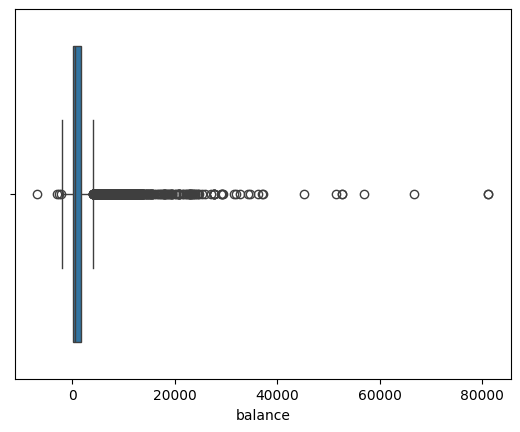

In [29]:
sns.boxplot(data=df, x="balance")
plt.show()

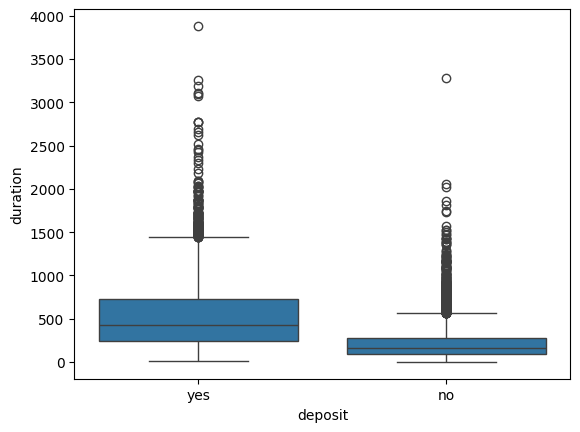

In [30]:
sns.boxplot(data=df, x="deposit", y="duration")
plt.show()

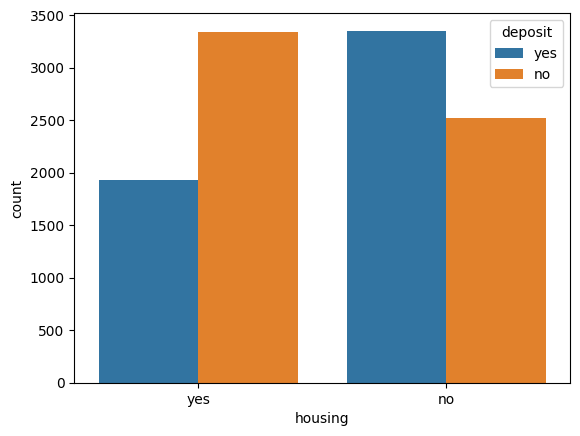

In [31]:
sns.countplot(data=df, x="housing", hue="deposit")
plt.show()

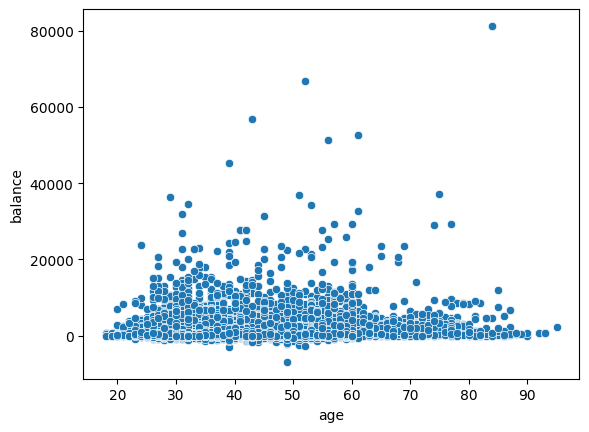

In [32]:
sns.scatterplot(data=df, x="age", y="balance")
plt.show()

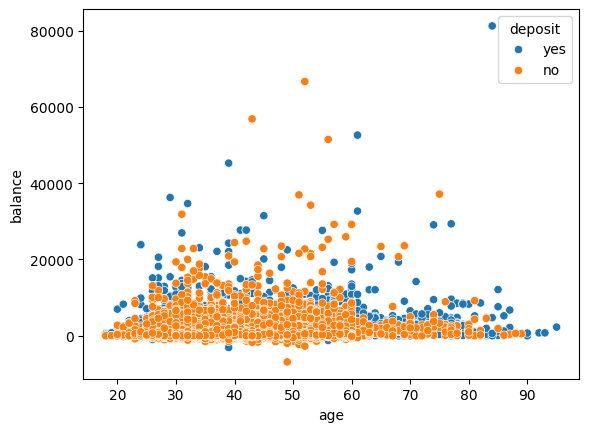

In [33]:
sns.scatterplot(data=df, x="age", y="balance", hue="deposit")
plt.show()

In [41]:
df["age"].corr(df["balance"])

np.float64(0.11229988859873165)

In [42]:
age_and_balance = df[["age", "balance"]]


In [43]:
age_and_balance.corr()

,age,balance
age,1.0000,0.1123
balance,0.1123,1.0000


In [44]:
correlation = df.corr(numeric_only=True)
correlation

,age,balance,duration,campaign,previous,deposit
age,1.000000,0.112300,0.000189,-0.005278,0.020169,NaN
balance,0.112300,1.000000,0.022436,-0.013894,0.030805,NaN
duration,0.000189,0.022436,1.000000,-0.041557,-0.026716,NaN
campaign,-0.005278,-0.013894,-0.041557,1.000000,-0.049699,NaN
previous,0.020169,0.030805,-0.026716,-0.049699,1.000000,NaN
deposit,NaN,NaN,NaN,NaN,NaN,NaN
